# Chapter 9: Recurrent Neural Networks

# 9.1.Working with Sequences
* Up until now, have previosuly only considered inputs of a single feature vector $\mathbf{x}\in \mathbb{R}^d$
* Now will focus on models capable of processing sequences that consist of an ordered list of feature vectors $\mathbf{x_1}, \dots, \mathbf{x_T}$ where each feature vector $\mathbf{x_t}$ is indexed by a time step $t\in \mathbb{Z}^+$ lying in $\mathbb{R}^d$
* Possible data
    * Extremely long streams of sensor readings
    * Randomly sampling subsequences of some predetermined length
    * Data may arrive as collection of sequences
* Previously when dealing with individual inputs, assumed they were sampled independently from same underlying distribution $P(X)$
* Now, we can still assume that the sequences themselves are sampled independently, we cannot assume that within each sequence, the data arriving at each time step are independent of each other. For example, it is likely that words that appear later in a document depend heavily on words occuring earlier in the document
* Possible Tasks
    * Predict a fixed target $y$ given sequentially structured input (e.g. sentiment classification based on movie review)
    * Predict a sequentially structured target $(y_1, \dots y_T)$ given a fixed input (e.g. image captioning)
    * Predict sequentially structured targets based on sequentially structured inputs (e.g. machine translation or video captioning)
        * Aligned: Input at each time step aligns with a corresponding target (e.g. part of speech tagging - processof markign up a word in text to correspond to a specific grammatical category such as noun, verb, adjective, adverb)
        * Unaligned: Where input and target to not necessarily exhibit step-for-step correspondence (e.g. machine translation)  
* First, will worry about unsupervised density modeling (a.k.a. sequence modeling). Given a collection of sequences, our goal is to estimate the probability mass function that tells us how likely we are to see any given sequence 

In [2]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l

### 9.1.1 Autoregressive Models
* First take look at actual sequence data to build up basic intuition and statistical tools - FTSE 100 index. At each time step $t\in \mathbb{Z}^+$, we observe the price $x_t$ of the index at that time
* Assume for now the only signal for predicting future price data is past price data i.e. we are interested in probability distribution $ P(x_t | x_{t-1}, \dots, x_1)$ 
* It can be difficult to estimate distributino over continuously valued random variable, trader would be happy to focus on few important statistics of distribution like expected value and variance
    * One Strategy for Estimating Conditional Expectation: $ \mathbb{E}[(x_t | x_{t-1}, \dots , x_1)]$ would be applying a linear regression model
    * Models that regress the value of a signal on previous vales of same signal are called "autoregressive models"
    * Need to account for varying input size with time step $t$. Number of inputs increases with amount of data encountered
* Latent Autoregressive Models
    * Although we may have long sequences at our disposal, it may not be necessary to look back so far in history when predicting the near future, and instead maybe content with a window of length $\tau$ and use only $x_{t-1}, \dots , x_{t-\tau}$ observations. Doing so, we see that that the number of arguments is always the same, at least for $t> \tau$. Allows us to train any linear model or deep network that requires fixed-length vectors as inputs
    * We may develop models that maintain some summary (compressed representation) $h_t$ of all past observations. At the same time update $h_t$ along with the prediction $\hat{x_t}$. This will result in models that estimate not only $x_t$ using $\hat{x_t} = P(x_t | h_t)$, but also updates of the form $h_t = g(h_{t-1}, x_{t-1})$. The namesake "latent" comes from the fact that $h_t$ is never observed
* To create training data from historical data, one typically creates examples by sampling windows randomly. In general, we do not expect time to stand still. However, we often assume that while the specific values of $x_t$ might change, the dynamics according to which each subsequent observation is generated given the previous observations do not. Dynamics that do not change are called "stationary"

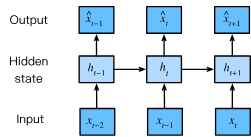
* A latent autoregressive model

### 9.1.2 Sequence Models
* We can reduce language modeling to autoregressive prediction by decomposing the joint density of a sequence $p(x_1, \dots x_T)$ into the product of conditional densities in a left-to-right fashion by applying the chain rule of probability
$$ P(x_1, \dots x_T) = P(x_1) \Pi_{t=2}^T P(x_t | x_{t-1}, \dots x_1)$$
* Note - if we are working with discrete signal such as words, then autoregressive model must be a probabilistic classifier, outputting a full probability distributino over the vocabulary for whatever word will come next, given the leftwards context

### 9.1.2.1 Markov Model
* When we can throw away the history beyond the previous $\tau$ steps without any loss in predictive power, we say that the sequence satisfies the Markov condition (i.e. the future is conditionally independent of the past, given its recent history)
    * $ \tau =1 $: First order Markov condition. The factorization of the joint probability distribution just becomes a product of probabilities of each word given the previous word in the sequence. 
    $$ P(x_1, ..., x_T) = P(x_1) \Pi_{t=2}^T P(x_t|x_{t-1})$$
    * $ \tau = k$: $k$-th order Markov model. 
* It is often useful to work with models that proceed as though Markov condition is fully satisfied, even when we know this to only be approximately true. Although the next text is dependent on all previous text that came before it, the benefits of going further back will diminish at some point.

### 9.1.2.2 The Order of Decoding
* Left-to-right decoding is preferred for language modeling (assuming language in question is read in that order)
    * More natural direction for us to think about
    * By factorizing in order, we can assign probabilities to arbitrarily long sequences using the same language model. To convert a probability over steps $1$ through $t$ into one that extends to word $t+1$, we simply multiply by the conditional probability of the additional token given the previous ones: $ P(x_{t+1}, \dots, x_1) = P(x_t, \dots x_1) \cdot P(x_{t+1}| x_t, \dots x_1)$
    * Stronger predictive models for predicting adjacent words than words at arbitrary other locations. While all orders of factorizations are valid, they do not necessarily represent the natural (causal) of the data. 
        * For example, we believe that future events cannot influence the past. Hence, if we change $x_t$, the distribution of past events will not change. In some contexts, it is easier to predict $P(x{t+1} | x_t)$ than to predict $ P(x_t | x_{t+1})$

### 9.1.3 Training
* Try out continuous valued synthetic data made of 1000 data steps will be made from 0.01 times the time step, along with additive gaussian noise
* Will extract training examples from this sequence, consisting of features and a label
* Will be assuming $\tau$-th order Markov condition 
    * Note, this will only result in $1000-\tau$ training examples/sequences since will lack sufficient history for labels/targets of $y_1, ..., y_{\tau}$
    * Although it is possible to pad the "missing" boundary data points with 0's or just extend the first available data point, but we will just be dropping these shorter sequences/examples

In [3]:
class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        self.save_hyperparameters()
        self.time = torch.arange(1, T + 1, dtype=torch.float32)
        self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2

    def get_dataloader(self, train):
        features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
        self.features = torch.stack(features, 1)
        self.labels = self.x[self.tau:].reshape((-1, 1))
        indices = slice(0, self.num_train) if train else slice(self.num_train, None)

        # https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py/#L250
        return self.get_tensorloader([self.features, self.labels], train, indices)


In [4]:
DataInstance = Data()
print("Time has shape: ", DataInstance.time.shape, '\n',DataInstance.time)
print("x has shape: ", DataInstance.x.shape, '\n', DataInstance.x)

Time has shape:  torch.Size([1000]) 
 tensor([   1.,    2.,    3.,    4.,    5.,    6.,    7.,    8.,    9.,   10.,
          11.,   12.,   13.,   14.,   15.,   16.,   17.,   18.,   19.,   20.,
          21.,   22.,   23.,   24.,   25.,   26.,   27.,   28.,   29.,   30.,
          31.,   32.,   33.,   34.,   35.,   36.,   37.,   38.,   39.,   40.,
          41.,   42.,   43.,   44.,   45.,   46.,   47.,   48.,   49.,   50.,
          51.,   52.,   53.,   54.,   55.,   56.,   57.,   58.,   59.,   60.,
          61.,   62.,   63.,   64.,   65.,   66.,   67.,   68.,   69.,   70.,
          71.,   72.,   73.,   74.,   75.,   76.,   77.,   78.,   79.,   80.,
          81.,   82.,   83.,   84.,   85.,   86.,   87.,   88.,   89.,   90.,
          91.,   92.,   93.,   94.,   95.,   96.,   97.,   98.,   99.,  100.,
         101.,  102.,  103.,  104.,  105.,  106.,  107.,  108.,  109.,  110.,
         111.,  112.,  113.,  114.,  115.,  116.,  117.,  118.,  119.,  120.,
         121.,  122.,  123

In [5]:
features = []
tau=4
T=1000
# 0-3, 1-4, 2-5, ... , 996-999

# i=0: x[0: 1000-4+0] = x[0:996]
# i=1: x[1: 1000-4+1] = x[1:997]
# i=2: x[2: 1000-4+2] = x[1:998] 
# i=3: x[3: 1000-4+3] = x[1:999]
features = [DataInstance.x[i : T- tau + i] for i in range(tau)]
print(len(features), len(features[0]))
# print(features)
features = torch.stack(features, dim=1)
print("features has shape: ", features.shape, '\n',features)
labels = DataInstance.x[tau:]
print("labels is of shape: ", labels.shape)
labels = labels.reshape((-1, 1))
print("labels is now of shape: ", labels.shape)

4 996
features has shape:  torch.Size([996, 4]) 
 tensor([[ 0.0362,  0.1293,  0.0175, -0.0573],
        [ 0.1293,  0.0175, -0.0573,  0.0015],
        [ 0.0175, -0.0573,  0.0015,  0.2776],
        ...,
        [-0.3011, -0.4492, -0.3290, -0.4098],
        [-0.4492, -0.3290, -0.4098, -0.5713],
        [-0.3290, -0.4098, -0.5713, -0.6549]])
labels is of shape:  torch.Size([996])
labels is now of shape:  torch.Size([996, 1])


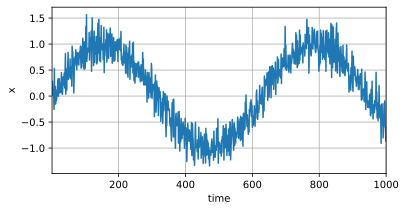

In [6]:
data = Data()
d2l.plot(X=data.time, Y=data.x, xlabel='time', ylabel='x', xlim=[1, 1000], figsize=(6, 3))

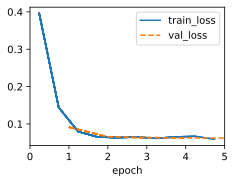

In [7]:
# Model will be standard linear regression

model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=5)
trainer.fit(model, data)

### 9.1.4 Prediction

In [8]:
model(data.features).shape # Pass through the features into the model to get predictions. Not calling attribute of model...

torch.Size([996, 1])

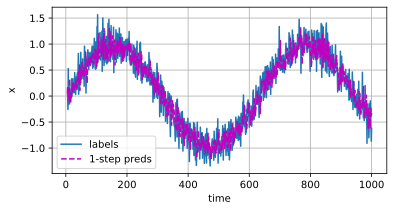

In [9]:
# "onestep" here refers to how far into future you predict, not how many features (time steps) used as input
onestep_preds = model(data.features).detach().numpy()
d2l.plot(data.time[data.tau:], [data.labels, onestep_preds], 'time', 'x', 
         legend=['labels', '1-step preds'], figsize=(6, 3))

* We hae observed sequence data up until time step 604 (num_train + tau). 
* What if now, we wished to make predictions several steps into the future?
    * Cannot directly compute the one-step-ahead prediction for time step 609 since we do not know the necessary inputs (we only have up until 604)
    * Can address this problem by plugging in our earlier predictions as inputs to our model for making subsequent predictions, projecting forward one step at a time, until reaching the desired time step
    $$\begin{aligned}
    \hat{x}_{605} &= f(x_{601}, x_{602}, x_{603}, x_{604}), \\
    \hat{x}_{606} &= f(x_{602}, x_{603}, x_{604}, \hat{x}_{605}), \\
    \hat{x}_{607} &= f(x_{603}, x_{604}, \hat{x}_{605}, \hat{x}_{606}),\\
    \hat{x}_{608} &= f(x_{604}, \hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}),\\
    \hat{x}_{609} &= f(\hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}, \hat{x}_{608}),\\
    &\vdots\end{aligned}
    $$
    * Generally, for an observed sequence $x_1, \dots , x_t$, its predicted output $\hat{x}_{t+k}$ at time step $t + k$ is called the $k$-step-ahead prediction. 
    * Since we observed up to $x_{604}$, its $k$-step-ahead prediction is $\hat{x}_{604+k}$. In other words, we will have to keep using own predictions to make multi-step-ahead predictions
* Notice below how predictions decay to a constant fairly quickly. This is due to errors building up

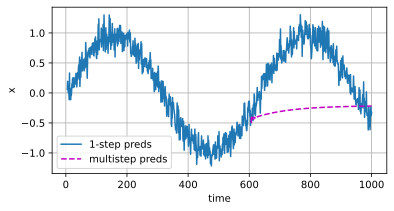

In [10]:
multistep_preds = torch.zeros(data.T)
multistep_preds[:] = data.x

for i in range(data.num_train + data.tau, data.T):
    multistep_preds[i] = model(
        multistep_preds[i - data.tau:i].reshape((1, -1)))
multistep_preds = multistep_preds.detach().numpy()

d2l.plot([data.time[data.tau:], data.time[data.num_train+data.tau:]],
         [onestep_preds, multistep_preds[data.num_train+data.tau:]], 'time',
         'x', legend=['1-step preds', 'multistep preds'], figsize=(6, 3))

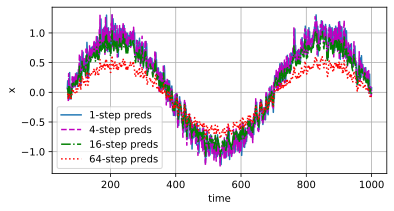

In [11]:
# Compute predictions on entire sequence for k = 1, 4, 16, 64

def k_step_pred(k):
    features = []
    for i in range(data.tau):
        features.append(data.x[i : i+data.T -data.tau - k + 1])
    # The (i+tau)-th element stores the (i+1)-step-ahead predictions
    for i in range(k):
        preds = model(torch.stack(features[i : i+data.tau], 1))
        features.append(preds.reshape(-1))
    return features[data.tau:]

steps = (1, 4, 16, 64)
preds = k_step_pred(steps[-1])
d2l.plot(data.time[data.tau+steps[-1]-1:],
         [preds[k - 1].detach().numpy() for k in steps], 'time', 'x',
         legend=[f'{k}-step preds' for k in steps], figsize=(6, 3))

### 9.1.5 Summary
* Big difference in difficulty between interpolation and extrapolation
* If you have a sequence, always respect the temporal order of the data when training (i.e. never train on future data)
* Sequence models require specialized statistical tools for estimations
    1. Autoregressive models
    1. Latent-Variable Autoregressive Models
* For causal models (e.g. time going forward), estimating the forward direction is typically a lot easier than the reverse direction 
* For an observed sequence up to time step $t$, its predicted output at time step $t+k$ is the $k$-step-ahead-prediction. As we predict further in time by increasing $k$, the errors accumulate and the quality of the predictino degrades, often dramatically

### 9.1.6 Exercises
1. Improve the model in the experiment of this section.
    1. Incorporate more than the past four observations? How many do you really need?
    1. How many past observations would you need if there was no noise? Hint: you can write $\sin$ and $\cos$ as a differential equation.
    1. Can you incorporate older observations while keeping the total number of features constant? Does this improve accuracy? Why?
    1. Change the neural network architecture and evaluate the performance. You may train the new model with more epochs. What do you observe?
1. An investor wants to find a good security to buy.
   They look at past returns to decide which one is likely to do well.
   What could possibly go wrong with this strategy?
1. Does causality also apply to text? To which extent?
1. Give an example for when a latent autoregressive model
   might be needed to capture the dynamic of the data.

Exercise #1

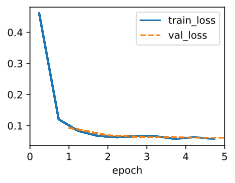

In [12]:
# 8 past observations (rather than 4 used before)
DataEx1 = Data(batch_size=16, T=1000, num_train=600, tau=8)

modelEx1 = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=5)
trainer.fit(modelEx1, DataEx1)

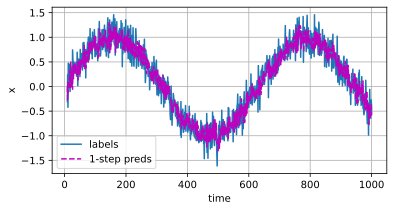

In [13]:
onestep_preds = modelEx1(DataEx1.features).detach().numpy()
d2l.plot(DataEx1.time[DataEx1.tau:], [DataEx1.labels, onestep_preds], 'time', 'x', 
         legend=['labels', '1-step preds'], figsize=(6, 3))

2. Need 2 two past observations. Need position and velocity to predict the next state (assuming no noise). Position and velocity can be extracted from the previous 2 data points/observations. Can think of as taylor approximation with small time step, so only need current state f(x), and current derivative/velocity f'(x). ALso, note that for the full taylor approximation, the higher order derivatives (for sine and cosine) can be calculated from raising f(x) or f'(x) to the appropriate exponent 

Exercise #2
* "Past performance is not indicative of future returns"

Exercise #3
* Yes, causality applies to text as future tokens depend on past tokens. 

Exercise #4
* When the entire sequence available is of relevance, but much older tokens are not as relevant and thus their representation can be compressed without loss in performance/meaning while the more recent tokens are kept within the joint distribution 

# 9.2 Converting Raw Text into Sequence Data
* We will often work with text data represented as sequences of words, characters, or word pieces
* Typical preprocessing pipelines follow the following steps:
    1. Load text as strings into memory
    1. Split the strings into tokens (e.g. words or characters)
    1. Build a vocabulary dictionary to associate each vocabulary element with a numerical index
    1. Convert the text into sequences of numerical indicies 

In [14]:
import collections
import random
import re
import torch
import os
import requests
import hashlib
from d2l import torch as d2l

### 9.2.1 Reading the Dataset
* Will be working with H. G. Well's The Time Machine book which as ~30,000 words
* Real application will typically involve significantly larger datasets, this is sufficient to demonstrate the preprocessing pipeline
* NOTE - will be ignoring punctuation and capitalization when preprocessing raw text for simplicity

In [15]:
DATA_HUB = dict()
DATA_URL = 'http://d2l-data.s3-accelerate.amazonaws.com/'

def download(url, folder='../data', sha1_hash=None):
    """Download a file to folder and return the local filepath."""
    if not url.startswith('http'):
        # For back compatability
        url, sha1_hash = DATA_HUB[url]
    os.makedirs(folder, exist_ok=True)
    fname = os.path.join(folder, url.split('/')[-1])

    # Check if hit cache
    if os.path.exists(fname) and sha1_hash:
        sha1 = hashlib.sha1()
        with open(fname, 'rb') as f:
            while True:
                data = f.read(1048576)
                if not data:
                    break
                sha1.update(data)
        if sha1.hexdigest() == sha1_hash:
            return fname
        
    # Download
    print(f'Downloading {fname} from {url}...')
    r = requests.get(url, stream=True, verify=True)
    with open(fname, 'wb') as f:
        f.write(r.content)
    return fname

class TimeMachine(d2l.DataModule): 
    """The Time Machine dataset."""
    def _download(self):
        fname = download(DATA_URL + 'timemachine.txt', self.root,
                             '090b5e7e70c295757f55df93cb0a180b9691891a')
        with open(fname) as f:
            return f.read()

data = TimeMachine()
raw_text = data._download()
raw_text[:60]

'The Time Machine, by H. G. Wells [1898]\n\n\n\n\nI\n\n\nThe Time Tra'

In [16]:
@d2l.add_to_class(TimeMachine)  
def _preprocess(self, text):
    # re.sub(pattern, replacement, text)
    # Replace anything that is not a an upper/lower case english character with a single space
    # Note without the "+", it will treat each non-letter match separately. With the "+", it 
    # will treat the whole non-match chunk as one (e.g. 123! as a single space)
    # .lower() changes everything to lowercase
    return re.sub('[^A-Za-z]+', ' ', text).lower() 

text = data._preprocess(raw_text)
len(text), text[:60]

(173428, 'the time machine by h g wells i the time traveller for so it')

### 9.2.2 Tokenization
* Each time step corresponds to 1 token
* What corresponds to a single token is a design choice
    * Set of all individual words 
    * Single characters
    * Components of words
* For this example, will be tokenizing text into sequence of single characters

In [17]:
@d2l.add_to_class(TimeMachine) 
def _tokenize(self, text):
    return list(text)

tokens = data._tokenize(text)
','.join(tokens[:30])

't,h,e, ,t,i,m,e, ,m,a,c,h,i,n,e, ,b,y, ,h, ,g, ,w,e,l,l,s, '

### 9.2.3 Vocabulary
* Tokens are still strings, but inputs to models must be numerical inputs
* Introduce a class for constructing vocabularies i.e. objects that associate each distinct token value with a unique index
    1. First, determine set of unique tokens in our training corpus
    1. Assign a numerical index to each token
        * Rare vocabulary elements are often dropped for convenience
        * Whenever we encounter a token at training/test-time that we have not seen before or previously dropped, we represent it by a special $"<unk>"$ token - signifying "unknown" value

In [18]:
print(tokens)
tokens = [token for line in tokens for token in line]
print(len(tokens))
print(tokens)

list1 = []
for line in tokens:
    for token in line:
        list1.append(token)
print(list1)

['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm', 'a', 'c', 'h', 'i', 'n', 'e', ' ', 'b', 'y', ' ', 'h', ' ', 'g', ' ', 'w', 'e', 'l', 'l', 's', ' ', 'i', ' ', 't', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 't', 'r', 'a', 'v', 'e', 'l', 'l', 'e', 'r', ' ', 'f', 'o', 'r', ' ', 's', 'o', ' ', 'i', 't', ' ', 'w', 'i', 'l', 'l', ' ', 'b', 'e', ' ', 'c', 'o', 'n', 'v', 'e', 'n', 'i', 'e', 'n', 't', ' ', 't', 'o', ' ', 's', 'p', 'e', 'a', 'k', ' ', 'o', 'f', ' ', 'h', 'i', 'm', ' ', 'w', 'a', 's', ' ', 'e', 'x', 'p', 'o', 'u', 'n', 'd', 'i', 'n', 'g', ' ', 'a', ' ', 'r', 'e', 'c', 'o', 'n', 'd', 'i', 't', 'e', ' ', 'm', 'a', 't', 't', 'e', 'r', ' ', 't', 'o', ' ', 'u', 's', ' ', 'h', 'i', 's', ' ', 'g', 'r', 'e', 'y', ' ', 'e', 'y', 'e', 's', ' ', 's', 'h', 'o', 'n', 'e', ' ', 'a', 'n', 'd', ' ', 't', 'w', 'i', 'n', 'k', 'l', 'e', 'd', ' ', 'a', 'n', 'd', ' ', 'h', 'i', 's', ' ', 'u', 's', 'u', 'a', 'l', 'l', 'y', ' ', 'p', 'a', 'l', 'e', ' ', 'f', 'a', 'c', 'e', ' ', 'w', 'a', 's', ' ', 'f',

In [19]:
class Vocab:
    """Vocabulary for text"""
    def __init__(self, tokens=[], min_freq=0, reserved_tokens=[]):
        # Flatten a 2D list if needed. For our case, is already 1D so skip. See cell above
        if tokens and isinstance(tokens[0], list):
            tokens = [token for line in tokens for token in line]

        # Count token frequencies
        # Sort key-value pairs by their count (the value is accessed by x: x[1]) and reversed, 
        # since we want descending (large to small)
        counter = collections.Counter(tokens)
        self.token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)

        # List of unique tokens
        self.idx_to_token = list(sorted(set(['<unk>'] + reserved_tokens + 
                                            [token for token, freq in self.token_freqs 
                                             if freq >= min_freq])))
        self.token_to_idx = {token: idx for idx, token in enumerate(self.idx_to_token)}
    
    # Special dunder method that automatically translates: len(vocab) ==> vocab.__len__()
    # Basically, just allows the use of the "len" method on this class  
    def __len__(self):
        return len(self.idx_to_token)
    
    # Special dunder method that defines what happens when you write: vocab[XXX]
    # Will translate this into: vocab.__getitems__('XXX')
    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]
    
    def to_tokens(self, indicies):
        if hasattr(indicies, '__len__') and len(indicies) > 1:
            return [self.idx_to_token[int(index)] for index in indicies]
        return self.idx_to_token[indicies]
    
    # @property lets you call a method as if it were a normal attribute
    # Without @property, would call it like a normal method: self.unk()
    # Since we have @property, we can call it just like: self.unk (as if were just a normal attribute)
    @property
    def unk(self): 
        """Index for the unkown token"""
        return self.token_to_idx['<unk>']

In [20]:
# Now, will construct vocabulary for dataset, converting sequence of strings into a list of numerical 
# indicies. 
# Note - no information has been list and can easily convert our dataset back to its original string representation 

vocab = Vocab(tokens)
indices = vocab[tokens[:10]]
print('indices:', indices)
print('words:', vocab.to_tokens(indices))

indices: [21, 9, 6, 0, 21, 10, 14, 6, 0, 14]
words: ['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm']


### 9.2.4 Putting It All Together
* Using classes & methods defined above, we package everything into the following "build" method - which will be added to the "TimeMachine" class, which returns "corpus" - a list of tokens and "vocab" - the vocabuluary of the The Time Machine corpus
* Modifications made here
    * Tokenize text into single characters (not words) to simplify training in later sections
    * "corpus" is a single list, not a list of token lists, since each text line in The Time machine dataset is not necessarily a sentence or paragraph

In [21]:
@d2l.add_to_class(TimeMachine)
def build(self, raw_text, vocab=None):
    tokens = self._tokenize(self._preprocess(raw_text))
    if vocab is None: vocab = Vocab(tokens)
    corpus = [vocab[token] for token in tokens]
    return corpus, vocab

corpus, vocab = data.build(raw_text)
len(corpus), len(vocab)
# 26 letters, unknown token, space token

(173428, 28)

In [22]:
type(corpus), type(vocab)

(list, __main__.Vocab)

### 9.2.5 Exploratory Language Statistics
* Basic words are the most frequently occuring
    * Previously, were filtered out from previous generations of text classifiers based on bag-of-words represented
    * They do carry meaning and not necessary to remove from from modern RNN/Transformer based neural networks
* Word frequency decays very quickly
    * 10th most frequent words is less than 1/5 as common as the most popular
    * Word frequency tends to follow a power law distribution (especially the Zipfian) as we go down the ranks 
    * Zipf's Law - frequency $n_i$ of the $i$-th most frequent word is: $ n_i \propto \frac{1}{i^{\alpha}}$, which can also be written as: $ \log{n_i} = -\alpha \log{i} + c$
    * If we want to model words by counting statistics, w will significantly overestimate the frequency of the tail (a.k.a. infrequent words), since tail is long even if each element in the tail contributes a small amount of probability density
* Also interested in frequency of word combinations like bigrams and trigrams to see fi they behave in same manner as single words (unigram) frequency

In [49]:
# Print the 10 most frequently occuring words

words = text.split()
vocab = Vocab(words)
vocab.token_freqs[:10]

[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

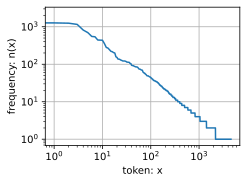

In [47]:
freqs = [freq for token, freq in vocab.token_freqs]
d2l.plot(freqs, xlabel='token: x', ylabel='frequency: n(x)', xscale='log', yscale='log')

In [48]:
len(freqs), len(vocab.token_freqs), len(vocab)

(4579, 4579, 4580)

In [25]:
for element in zip(words[:-1], words[1:]):
    print(element)

('the', 'time')
('time', 'machine')
('machine', 'by')
('by', 'h')
('h', 'g')
('g', 'wells')
('wells', 'i')
('i', 'the')
('the', 'time')
('time', 'traveller')
('traveller', 'for')
('for', 'so')
('so', 'it')
('it', 'will')
('will', 'be')
('be', 'convenient')
('convenient', 'to')
('to', 'speak')
('speak', 'of')
('of', 'him')
('him', 'was')
('was', 'expounding')
('expounding', 'a')
('a', 'recondite')
('recondite', 'matter')
('matter', 'to')
('to', 'us')
('us', 'his')
('his', 'grey')
('grey', 'eyes')
('eyes', 'shone')
('shone', 'and')
('and', 'twinkled')
('twinkled', 'and')
('and', 'his')
('his', 'usually')
('usually', 'pale')
('pale', 'face')
('face', 'was')
('was', 'flushed')
('flushed', 'and')
('and', 'animated')
('animated', 'the')
('the', 'fire')
('fire', 'burned')
('burned', 'brightly')
('brightly', 'and')
('and', 'the')
('the', 'soft')
('soft', 'radiance')
('radiance', 'of')
('of', 'the')
('the', 'incandescent')
('incandescent', 'lights')
('lights', 'in')
('in', 'the')
('the', 'lilie

In [26]:
# words[:-1] = Everything up until last word
# words[1:]  = Everything 
bigram_tokens = ['--'.join(pair) for pair in zip(words[:-1], words[1:])]
bigram_vocab = Vocab(bigram_tokens)
bigram_vocab.token_freqs[:10]

[('of--the', 309),
 ('in--the', 169),
 ('i--had', 130),
 ('i--was', 112),
 ('and--the', 109),
 ('the--time', 102),
 ('it--was', 99),
 ('to--the', 85),
 ('as--i', 78),
 ('of--a', 73)]

In [27]:
len(bigram_tokens), len(words)

(32774, 32775)

In [28]:
trigram_tokens = ['--'.join(triple) for triple in zip(
    words[:-2], words[1:-1], words[2:])]
trigram_vocab = Vocab(trigram_tokens)
trigram_vocab.token_freqs[:10]

[('the--time--traveller', 59),
 ('the--time--machine', 30),
 ('the--medical--man', 24),
 ('it--seemed--to', 16),
 ('it--was--a', 15),
 ('here--and--there', 15),
 ('seemed--to--me', 14),
 ('i--did--not', 14),
 ('i--saw--the', 13),
 ('i--began--to', 13)]

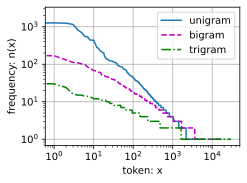

In [29]:
# Notice how even bigrams and trigrams seem to be following Zipf's law, albeit with a smaller alpha exponent
# Also note the number of distinct n-grams (n>1) is not that large
# Indicates that there is a lot of structure in language and that many n-grams occur rarely

bigram_freqs = [freq for token, freq in bigram_vocab.token_freqs]
trigram_freqs = [freq for token, freq in trigram_vocab.token_freqs]
d2l.plot([freqs, bigram_freqs, trigram_freqs], xlabel='token: x',
         ylabel='frequency: n(x)', xscale='log', yscale='log',
         legend=['unigram', 'bigram', 'trigram'])

### 9.2.6 Summary
* Text is among the most common forms of sequence data in deep learning
* Common choice for what constitutes a token are:
    1. Characters
    1. Words
    1. Word pieces
* To preprocess text we usually:
    1. Split text into tokens
    1. Build a vocabulary to map token strings to numerical indicies
    1. Convert text data into token indices for models to manipulate
* In practice, frequency of words and n-grams tends to follow Zipf's law

### 9.2.7 Exercises
1. In the experiment of this section, tokenize text into words and vary the `min_freq` argument value of the `Vocab` instance. Qualitatively characterize how changes in `min_freq` impact the size of the resulting vocabulary.
1. Estimate the exponent of Zipfian distribution for unigrams, bigrams, and trigrams in this corpus.
1. Find some other sources of data (download a standard machine learning dataset, pick another public domain book,
   scrape a website, etc). For each, tokenize the data at both the word and character levels. How do the vocabulary sizes compare with *The Time Machine* corpus at equivalent values of `min_freq`. Estimate the exponent of the Zipfian distribution corresponding to the unigram and bigram distributions for these corpora. How do they compare with the values that you observed for *The Time Machine* corpus?

Exercise #1
* Tokenize into words instead of single characters
* Vary min_freq argument of Vocab instance and do qualitative characterization of how changing min_freq impacts size of resultant vocabulary

In [30]:
data = TimeMachine()
raw_text = data._download()

raw_text

'The Time Machine, by H. G. Wells [1898]\n\n\n\n\nI\n\n\nThe Time Traveller (for so it will be convenient to speak of him)\nwas expounding a recondite matter to us. His grey eyes shone and\ntwinkled, and his usually pale face was flushed and animated. The\nfire burned brightly, and the soft radiance of the incandescent\nlights in the lilies of silver caught the bubbles that flashed and\npassed in our glasses. Our chairs, being his patents, embraced and\ncaressed us rather than submitted to be sat upon, and there was that\nluxurious after-dinner atmosphere when thought roams gracefully\nfree of the trammels of precision. And he put it to us in this\nway--marking the points with a lean forefinger--as we sat and lazily\nadmired his earnestness over this new paradox (as we thought it)\nand his fecundity.\n\n\'You must follow me carefully. I shall have to controvert one or two\nideas that are almost universally accepted. The geometry, for\ninstance, they taught you at school is founded on a

In [33]:
# Remove non-English alphabet characters
cleaned1 = re.sub('[^A-Za-z]+', ' ', raw_text).lower()
print("cleaned: ", len(cleaned1), cleaned1)

# Split into list of words
list_of_words = cleaned1.split()
print(list_of_words)

vocabEx1 = Vocab(tokens=list_of_words, min_freq=0, reserved_tokens=[])

# Doing the below will yield (173428, 4580) because 
# corpus, vocab = data.build(raw_text, vocab=vocabEx1)
# len(corpus), len(vocab)

corpusEx1 = vocabEx1[list_of_words]
print(len(corpusEx1), len(vocabEx1))
print("corpus: ", corpusEx1)
print("vocabEx1: ", vocabEx1)


# Copied from the Vocab class:
def __getitem__(self, tokens):
    if not isinstance(tokens, (list, tuple)):
        return self.token_to_idx.get(tokens, self.unk)
    return [self.__getitem__(token) for token in tokens]
# When: vocabEx1[list_of_words] is called, will see on first run that it is a list and directly go for 
# the "return" line
# "return" line will recursively call the function and now run it on the for each of the elements of list_of_words, 
# which will noe ba assigned numerical indexes by: self.token_to_idx.get(tokens, self.unk)

cleaned:  173428 the time machine by h g wells i the time traveller for so it will be convenient to speak of him was expounding a recondite matter to us his grey eyes shone and twinkled and his usually pale face was flushed and animated the fire burned brightly and the soft radiance of the incandescent lights in the lilies of silver caught the bubbles that flashed and passed in our glasses our chairs being his patents embraced and caressed us rather than submitted to be sat upon and there was that luxurious after dinner atmosphere when thought roams gracefully free of the trammels of precision and he put it to us in this way marking the points with a lean forefinger as we sat and lazily admired his earnestness over this new paradox as we thought it and his fecundity you must follow me carefully i shall have to controvert one or two ideas that are almost universally accepted the geometry for instance they taught you at school is founded on a misconception is not that rather a large thin

In [42]:
vocabEx1_P1 = Vocab(tokens=list_of_words, min_freq=5, reserved_tokens=[])
vocabEx1_P2 = Vocab(tokens=list_of_words, min_freq=10, reserved_tokens=[])
vocabEx1_P3 = Vocab(tokens=list_of_words, min_freq=50, reserved_tokens=[])

print(len(vocabEx1_P1), len(vocabEx1_P2), len(vocabEx1_P3))

825 400 85


Exercise #2
* Curve Fitting exercise with unigrams
* Will be skipping exponents for bigrams and trigrams since trivial w.r.t. unigrams and not good use of time. Not particularly insightful

In [55]:
words = text.split()
vocab = Vocab(words)
freqs = [freq for token, freq in vocab.token_freqs]

print(len(freqs), freqs[4578])
print(freqs)

4579 1
[2261, 1267, 1245, 1155, 816, 695, 552, 541, 443, 440, 437, 354, 281, 270, 243, 221, 216, 204, 200, 158, 152, 137, 137, 134, 129, 127, 123, 122, 122, 122, 120, 118, 114, 114, 113, 113, 112, 106, 105, 103, 94, 93, 92, 92, 91, 89, 88, 87, 86, 85, 85, 85, 84, 84, 82, 79, 77, 75, 74, 74, 74, 73, 72, 71, 70, 70, 70, 69, 66, 62, 61, 60, 59, 59, 57, 57, 57, 55, 54, 54, 53, 52, 51, 50, 49, 49, 49, 49, 49, 49, 48, 48, 47, 47, 46, 46, 46, 46, 45, 45, 44, 43, 43, 43, 42, 42, 41, 40, 40, 40, 40, 39, 38, 38, 37, 37, 37, 37, 37, 36, 36, 36, 36, 36, 36, 35, 35, 35, 35, 35, 34, 34, 34, 34, 34, 34, 33, 33, 33, 32, 32, 32, 32, 32, 31, 31, 31, 30, 30, 30, 29, 29, 28, 28, 28, 28, 28, 28, 27, 27, 27, 27, 27, 26, 26, 26, 26, 26, 26, 26, 25, 25, 25, 25, 24, 24, 24, 24, 24, 23, 23, 23, 23, 23, 23, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 21, 21, 21, 21, 21, 21, 21, 21, 21, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 18, 18, 18, 18, 18, 17, 17, 17, 

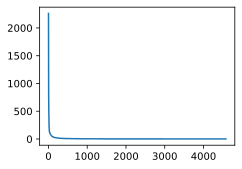

In [61]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(1, len(freqs)+1)
y = np.array(freqs)

plt.plot(x, y)

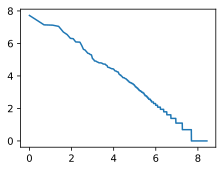

In [62]:
log_x = np.log(x)
log_y = np.log(y)

plt.plot(log_x, log_y)

In [63]:
m, b = np.polyfit(log_x, log_y, deg=1)

a = -m

print(f"a = {a}")
print(f"b = {b}")

a = 1.0352906770079615
b = 8.424112526680622


a = 1.0353
b = 8.4241


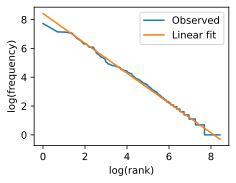

In [64]:
log_y_fit = m * log_x + b

print(f"a = {a:.4f}")
print(f"b = {b:.4f}")

plt.plot(log_x, log_y, label='Observed')
plt.plot(log_x, log_y_fit, label='Linear fit')

plt.xlabel('log(rank)')
plt.ylabel('log(frequency)')
plt.legend()
plt.show()

Exercise #3
* Skip for now. I'll have to do this in detail later when I do my own thing 

# 9.3 Language Models

In [65]:
import torch
from d2l import torch as d2l

### 9.3.1 Learning Language Models

* Apply basic probability rules, such as conditional probability, to autoregressive language modeling.

* Markov models and n-grams: probability formulas can depend on:

  * 1 variable: unigram
  * 2 variables: bigram
  * 3 variables: trigram
* Word Frequency
  * Assume our training set is a large text corpus, such as all Wikipedia entries, Project Gutenberg, and text posted on the web.
  * We can calculate the frequency of individual words occurring in the training set. We can also estimate the occurrence frequencies of word pairs or three-word combinations.
  * However, recall from *The Time Machine* example that many three-word combinations are quite rare.
  * Unless we provide some method for assigning such word combinations a nonzero probability, we will not be able to use them effectively in a language model.
  * If a dataset is small and/or the word combinations are rare, we might not observe even a single occurrence of them.
* Laplace Smoothing
  * Add a small constant or smoothing term to the observed counts.
  * Denote by $n$ the total number of words in the training set and by $m$ the number of unique words:
    $$
    \begin{aligned}
    \hat{P}(x) & = \frac{n(x) + \epsilon_1/m}{n + \epsilon_1}, \
    \hat{P}(x' \mid x) & = \frac{n(x, x') + \epsilon_2 \hat{P}(x')}{n(x) + \epsilon_2}, \
    \hat{P}(x'' \mid x,x') & = \frac{n(x, x',x'') + \epsilon_3 \hat{P}(x'')}{n(x, x') + \epsilon_3}.
    \end{aligned}
    $$
  * Here, $\epsilon_1$, $\epsilon_2$, and $\epsilon_3$ are hyperparameters.
  * Take $\epsilon_1$ as an example:
    * When $\epsilon_1 = 0$, no smoothing is applied.
    * As $\epsilon_1 \to +\infty$, $\hat{P}(x)$ approaches the uniform probability $1/m$.
* Models like these become unwieldy and undesirable for several reasons:
  1. Many n-grams occur very rarely, making simple Laplace smoothing rather unsuitable for language modeling.
  2. We need to store the counts of all observed n-grams.
  3. These models do not address the semantic meaning of words; they only model the statistical likelihood of word combinations. Thus, it is difficult to adapt such models to additional contexts, whereas deep learning-based language models are much better suited for this.
  4. Long word sequences are almost certain to be novel. A model that simply relies on the frequencies of previously observed word sequences is therefore bound to perform poorly on them.
* All subsequent discussions on language modeling will focus on using neural networks to address these limitations.


### 9.3.2 Perplexity
* Evaluating quality of language model. Should be able to predict with high accuracy of tokens that come next
8 Might measure quality of model by computing likelihood of sequence
* Information Theory based Approach
    * If we want to compress text, we cna ask about predicting the next token given the current set of tokens, where a better language model would predict the next token more accurately and thus require less bits to compress the sequence
    * Can measure it by the cross-entropy loss averaged over all the $n$ tokens of a sequence
    $$ \frac{1}{n} \sum_{t=1}^n -\log{P(x_t | x_{t-1}, \dots, x_1)} $$
    * $P$: Given by a language model
    * $x_t$: Actual token observed at time step $t$ from the sequence
    * For historical reasons, NLP researchers prefer a measure called _perplexity_, which is just the exponential of the above expression 
    $$ \exp{\left(-\frac{1}{n} \sum_{t=1}^n \log{P(x_t | x_{t-1}, \dots, x_1)}\right)}$$
    * Perplexity = $0$: Best case scenario where model always perfectly estimates probability of target token as 1
    * Perplexity = $+\inf$: Model always predicts the probability of the target token as 0
    * As a baseline, model predicts uniform distribution over all the available tokens of the vocabulary
        * $P(x_t | x_{t-1}, \dots, x_1) = 1/|V|$
        * Since is constant, can be factored out of summation to find that the perplexity of a uniform base language model is $|V|$, which provides an upper bound for the language model in question to beat

### 9.3.3 Partitioning Sequences
* Assume model processes a minibatch of sequences with predefined length at a time
* Q: How to read minibatches of input sequences and target sequences at random
* Suppose dataset of sequence of $T$ tokens indicies in _corpus_
* We will partition it into subsequences, where each subsequence has $n$ tokens (i.e. time steps)
* We can also introduce some randomness by the following
    * At the begining of each epoch, discard the first $d\in [0, n)$ draw from a uniform distribution
    * Rest of the sequence is partitioned into $m = \lfloor (T-d)/n \rfloor$ subsequences 
    * $\mathbf{x_t} = [x_t, ..., x_{t+n-1}]$ the length-$n$ subsequence starting from token $x_t$ at time step $t$
    * Resultant $m$ partitioned subsequences are $\mathbf{x_d}, \mathbf{x_{d+n}}, \mathbf{x_{d+n(m-1)}}$
    * Each subsequence will be used as an input sequence into the language model
* For language modeling, the goal is to predict the next token based on the tokens we have seen so far; hence, the targets (labels) are the original sequence shifted by one token
* Target sequence for any input sequence $\mathbf{x_t}$ is $\mathbf{x_{t+1}}$ with length $n$

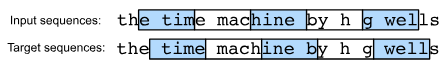
* 5 pairs of input and target sequences with $n=5$ and $d=2$

In [66]:
@d2l.add_to_class(d2l.TimeMachine)  
def __init__(self, batch_size, num_steps, num_train=10000, num_val=5000):
    super(d2l.TimeMachine, self).__init__()
    self.save_hyperparameters()
    corpus, self.vocab = self.build(self._download())
    array = torch.tensor([corpus[i:i+num_steps+1]
                        for i in range(len(corpus)-num_steps)])
    self.X, self.Y = array[:,:-1], array[:,1:]


@d2l.add_to_class(d2l.TimeMachine)  
def get_dataloader(self, train):
    idx = slice(0, self.num_train) if train else slice(self.num_train, self.num_train + self.num_val)
    return self.get_tensorloader([self.X, self.Y], train, idx)

In [69]:
data = d2l.TimeMachine(batch_size=2, num_steps=10)
for X, Y in data.train_dataloader():
    print('X:', X, '\nY:', Y)
    print('X has length: ', X.shape)
    print('Y has length: ', Y.shape)
    break

X: tensor([[ 2, 13, 13, 10, 15,  6,  0, 20, 22,  3],
        [21,  0, 20, 22,  8,  8,  6, 20, 21,  6]]) 
Y: tensor([[13, 13, 10, 15,  6,  0, 20, 22,  3, 20],
        [ 0, 20, 22,  8,  8,  6, 20, 21,  6,  5]])
X has length:  torch.Size([2, 10])
Y has length:  torch.Size([2, 10])


### 9.3.4 Summary and Discussion
* Language models estimate joint probability of text sequence
* For long sequences, $n$-grams provide a convenient model by truncating dependence, but there is not enough frequency to deal with infrequent word combinations so Laplace smoothing is introduced
* Neural language modeling will be the focus in subsequent sections
* To train language models, we can randomly sample pairs of input sequences and target sequences in minibatches
* Use perplexity to measure language model quality after training
* Can be scaled up with increased data size, model size, and training compute 

### 9.3.5 Exercises
1. Suppose there are 100,000 words in the training dataset. How much word frequency and multi-word adjacent frequency does a four-gram need to store?
1. How would you model a dialogue?
1. What other methods can you think of for reading long sequence data?
1. Consider our method for discarding a uniformly random number of the first few tokens at the beginning of each epoch.
    1. Does it really lead to a perfectly uniform distribution over the sequences on the document?
    1. What would you have to do to make things even more uniform? 
1. If we want a sequence example to be a complete sentence, what kind of problem does this introduce in minibatch sampling? How can we fix it?

Exercise #1
* 100,000 words in training dataset
* Only need to store 4-grams that actually occur in training dataset, not all possible 4-grams which would be alot
* 99,997 would be the upper bound since some 4-grams would repeat

Exercise #2
* Include tokens to indicate wheather person 1 or person 2 is talking at the begining of their speech, if you want to be explicit about it

Exercise #3
* First, restrict range of valid starting tokens based on if there are enough subsequent tokens for desired sequence length + target token
* Randomly draw from restricted range. Draw corresponding sequence and use that as training sequence
* Would have a lot more overlap than the partitioned subsequence method but more variance/randomness

Exercise #4
* Not really uniform distribution, since depending on $d$, the number of subsequences generated will be different
* To get much more uniform, use the method described above in the answer for Exercise 3 - just uniformly sample the starting token from the entire training sequence

Exercise #5
* Minibatch sampling scheme does not necessarily respect the start/end of sequence
* If we want most sequences to be complete sequences, can terminate training subsequences early if the last sentence bleeds over the alloted subsequence length and fill with filler/padding tokens

# 9.4 Recurrent Neural Networks
* Previously only described Markov models with $n$-grams for language modeling where conditional probability of token $x_t$ at time step $t$ only depends on the $n-1$ previous tokens 
* If we wanted to incorporate the possible effect of tokens earlier than time step $t-(n-1)$ on $x_t$, we need to increase $n$, but that increases the number of model parameters exponentially as we would need to store $|V|^n$ numbers for a vocabulary of size $V$
* Thus, it is preferable to use a latent variable model: $P(x_t | x_{t-1}, \dots , x_1) \approx P(x_t | h_{t-1})$ 
    * $h_{t-1}$ is the hidden state that stores the sequence information up to time step $t-1$
    * In general the hidden state at any time step $t$ could be computed based on both the current input $x_t$ and the previous hidden state $h_{t-1}$: $h_t = f(x_t, h_{t-1})$

In [70]:
import torch
from d2l import torch as d2l

### 9.4.1 Neural Networks without Hidden States
* Consider a MLP with a single hidden layer. Let hidden layer's activation function be $\phi$
* Given a minibatch of examples $X\in \mathbb{R}^{n\times d}$ with batch size $n$ and $d$ inputs, the hidden layer output $\mathbf{H} \in \mathbb{R}^{n\times h}$ is calculated the equation below where $\mathbf{W_{xh} \in \mathbb{R}^{d\times h}}$ and $\mathbf{b_h} \in \mathbb{R}^{1\times h} $. Note we have to apply broadcasting during summation. 
$$ \mathbf{H} = \phi ( \mathbf{XW_{xh}} + \mathbf{b_h})$$
* The hidden layer's output is used as input of the output layer, which is given by the equation below where: $\mathbf{O}\in \mathbb{R}^{n\times q}$ is the output variable, $\mathbf{W_{hq} \in \mathbb{R}^{h\times q}}$ is the weight parameter, and $\mathbf{b_q} \in \mathbb{R}^{1\times 1}$ is the bias parameter of the output layer. If it is a classification problem we can use $\mathbf{softmax(O)}$ to compute the probability distribution of the output categories.  
$$ \mathbf{O} = \mathbf{HW_{hq}} + \mathbf{b_q}$$

### 9.4.2 Recurrent Neural Networks with Hidden States
$$ H_t = \phi ( X_t W_{wh} + H_{t-1}W_{hh} + b_h)$$
* Where:
    * $X_t \in \mathbb{R}^{n\times d}$: Minibatch of inputs at time step $t$
        * For a minibatch of $n$ sequence examples, each row of $X_t$ corresponds to one example at time step $t$ from the sequence
    * $H_t \in \mathbb{R}^{n\times h}$: Hidden output layer at output time $t$. Unlike MLP, we save hidden layer output $H_{t-1}$ from previous time step and introduce a new weight parameter $W_{hh}\in \mathbb{R}^{h\times h}$ to describe how to use hidden layer output of previous time step in current time step
* Called Recurrent Neural Networks (RNNs) because hidden state uses same definition of previous time step in the current time step, and thus the computation is _recurrent_. 
* For time step $t$, the output layer is similar to the computation in the MLP
$$ O_t = H_t W_{hq} + b_q$$
* Where:
    * $W_{xh}\in \mathbb{R}^{d\times h}$: Weights from input sequence to output of hidden layer
    * $W_{hh}\in \mathbb{R}^{h\times h}$: Weights from hidden layer to output of hidden layer
    * $b_h\in \mathbb{R}^{1\times h}$: Bias of the hidden layer
    * $W_{hq}\in \mathbb{R}^{h\times q}$: Weights of the output layer
    * $b_q \in \mathbb{R}^{1\times 1}$: Bias of the output layer
* Note - parametrization cost of an RNN does NOT grow as number of time steps increases 

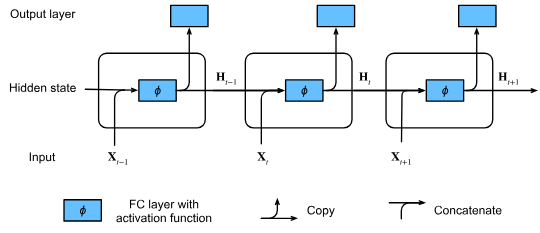

* NOTE: Calculation of $X_t W_{xh} + H_{t-1}W_{hh}$ for the hidden state is equivalent to matrix multiplication of concatenation of $X_t$ and $H_{t-1}$ and concatenation of $W_{xh}$ and $W_{hh}$. 
    * $X_t \in \mathbb{R}^{n\times d}$
    * $W_{xh}\in \mathbb{R}^{d\times h}$
    * $H_t \in \mathbb{R}^{n\times h}$
    * $W_{hh}\in \mathbb{R}^{h\times h}$
    * $ \begin{bmatrix} X_t & H_{t-1}  \end{bmatrix}  \begin{bmatrix} W_{xh} \\ W_{hh} \end{bmatrix} \in \mathbb{R}^{n \times (d+h)} \times \mathbb{R}^{(d+h)\times h} = \mathbb{R}^{n\times h}$
    * Additionally, code in cell below corroborates this

In [75]:
X    = torch.randn(3, 1)
W_xh = torch.randn(1, 4)
H    = torch.randn(3, 4)
W_hh = torch.randn(4, 4)
torch.matmul(X, W_xh) + torch.matmul(H, W_hh)

tensor([[-1.9198,  2.0794, -0.7647,  1.4323],
        [ 2.6401, -1.0792,  3.2017, -1.7490],
        [-0.6069,  2.7322, -0.1434,  1.6528]])

In [76]:
torch.matmul(torch.cat((X, H), 1), torch.cat((W_xh, W_hh), 0))

tensor([[-1.9198,  2.0794, -0.7647,  1.4323],
        [ 2.6401, -1.0792,  3.2017, -1.7490],
        [-0.6069,  2.7322, -0.1434,  1.6528]])

### 9.4.3 RNN-Based Character-Level Language Models
* How RNNs can be used to build a language model
* Let minibatch size be one, and the sequence of the text be "machine"
* To simplify training in subsequent sections, we tokenize text into characters rather than words and consider a _character-level language model_

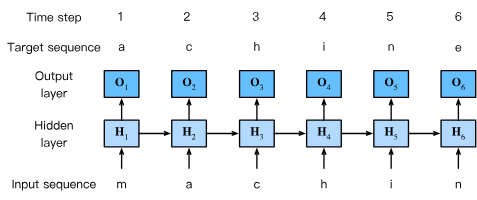
* Example of character-level language model based on RNN
* During the training process, we run a softmax operaton on the output from the output layer for each time step, and then use the cross-entropy loss to compute the error between the model output and the target
* Due to the recurrent computation of the hidden state in the hidden layer, the output $O_3$ of time step $3$ is determined by the text sequence "m", "a", and "c". 
* Since the next character of the sequence in the training data is "h", the loss of time step $3$ will depend on the probability distribution of the next character generated based on the feature sequence "m", "a", "c" and the target "h" of this time step 
* In practice, each token is represented by a $d$-dimensional vector and we use a batch size $n>1$. Thus, the input $X_t$ at time step $t$ will be an $n\times d$ matrix, as previously discussed

### 9.4.4 Summary
* A neural network that uses recurrent computation for hidden states is called a "recurrent neural network"
* Hidden state of an RNN can capture historical information of the sequence up to the current time step
* For RNNs, the number of model parameters does not grow with increasing time steps

### 9.4.5 Exercises
1. If we use an RNN to predict the next character in a text sequence, what is the required dimension for any output?
1. Why can RNNs express the conditional probability of a token at some time step based on all the previous tokens in the text sequence?
1. What happens to the gradient if you backpropagate through a long sequence?
1. What are some of the problems associated with the language model described in this section?

Exercise #1
* Output dimension should be the same as the vocabuluary size (i.e. how many characters there are in this case) since should be generating probability distribution over all of them

Exercise #2
* Due to the hidden state implicitly storing information about all previous tokens

Exercise #3
* If backpropogating through a long sequence, risk running into the exploding/vanishing gradients problem
* More severe than standard MLPs since sequence in question could be much longer than the layer count in "reasonable" MLPs

Exercise #4
* Using character level tokens restricts ability to learn relationships between words themselves. Also exaserbates the long-range dependency problem 
* Using a single linear layer for each recurrent seems restrictive, seems like there is not enough complexity to capture all complex relationships
* Hidden layer would be "overwritten" over a long sequence and seems insufficient for more complex representations/meanings

# 9.5 Recurrent Neural Network Implementation from Scratch
* Implement an RNN from scratch
* Train RNN as a character-level language model
* Training corpous is entire text of H.G. Well's _The Time Machine_

In [77]:
%matplotlib inline
import math
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

### 9.5.1 RNN Model

In [ ]:
class RNNScratch(d2l.Module):
    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W_xh = nn.Parameter(torch.randn(num_inputs, num_hiddens)  * sigma)
        self.W_hh = nn.Parameter(torch.randn(num_hiddens, num_hiddens) * sigma)
        self.b_h  = nn.Parameter(torch.zeros(num_hiddens))

    def forward(self, inputs, state=None):
        if state is None:
            state = torch.zeros((inputs.shape[1], self.num_hiddens), device=inputs.device)
        else:
            state, = state
        outputs = []
        for X in inputs: # Inputs shape: (num_steps, batch_size, num_inputs) = (T, n, d)
            state = torch.tanh(torch.matmul(X, self.W_xh) + torch.matmul(state, self.W_hh) + self.b_h)
            outputs.append(state)
        return outputs, state # Returns list of all states (including last one), and also the last state

# Feeding a minibatch of input sequences into RNN model
batch_size  = 2
num_inputs  = 16
num_hiddens = 32 
num_steps   = 100
rnn = RNNScratch(num_inputs, num_hiddens)
X = torch.ones((num_steps, batch_size, num_inputs))
outputs, state = rnn(X)

In [81]:
# Check whether RNN model produces results of the correct shapes to ensure
# dimensionality of hidden state remains unchanged

def check_len(a, n):  
    """Check the length of a list."""
    assert len(a) == n, f'list\'s length {len(a)} != expected length {n}'

def check_shape(a, shape):  
    """Check the shape of a tensor."""
    assert a.shape == shape, \
            f'tensor\'s shape {a.shape} != expected shape {shape}'

check_len(outputs, num_steps)
check_shape(outputs[0], (batch_size, num_hiddens))
check_shape(state, (batch_size, num_hiddens))

### 9.5.2 RNN-Based Language Model
* When training language models, the inputs and outputs are from the same vocabulary, and hence they have the same dimension (vocabuluary size)
* Use perplexity to evaluate the model
* One-Hot Encoding
    * Recall each token is representing by a numerical index indicating its position in the vocabuluary
    * A neural network with a single input node (at each time step) where the index could be fed in as a scalar value. This would work when dealing with numerical inputs like price or temperature when two values that are close together can be treated similarly, but this does not make sense in context of language modeling, as there is no garuntee that 45, 46 indices correspond to words in the vocabulary of similar/related semantic meaning
* When dealing with categorical data, the most common data is to represent each item by one-hot encoding that is of length of the size of the vocabuluary $N$, where all entries are set to 0 except for the entry corresponding to token in question, which is set to 1
* Language model uses a fully connected output layer to transform RNN outputs into token predictions at each time step

In [ ]:
class RNNLMScratch(d2l.Classifier):  
    """The RNN-based language model implemented from scratch.
    Uses an RNNScratch object/instance, but does not inherit from it

    RNNScratch: Processes sequences and computes hidden states
    RNNLMScratch: Uses hidden states to predict vocab tokens and be a trainable object
    """
    def __init__(self, rnn, vocab_size, lr=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.init_params()

    def init_params(self):
        self.W_hq = nn.Parameter(torch.randn(self.rnn.num_hiddens, self.vocab_size) * self.rnn.sigma)
        self.b_q  = nn.Parameter(torch.zeros(self.vocab_size))

    def training_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        self.plot('ppl', torch.exp(l), train=True)
        return l

    def validation_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        self.plot('ppl', torch.exp(l), train=False)

    def one_hot(self, X):
        """
        Converts numerical indices to one-hot encoding vectors
        i.e. 2 => [0, 0, 1, 0,...,0_n]

        Output shape: (num_steps, batch_size, vocab_size)
        """
        return F.one_hot(X.T, self.vocab_size).type(torch.float32)

    def output_layer(self, rnn_outputs):
        outputs = [torch.matmul(H, self.W_hq) + self.b_q for H in rnn_outputs]
        return torch.stack(outputs, 1)

    def forward(self, X, state=None):
        embs = self.one_hot(X)
        rnn_outputs, _ = self.rnn(embs, state) # rnn returns: outputs (list of hidden states), state
        return self.output_layer(rnn_outputs)
    
# Checking whether forward computaio produces outputs with the correct shape
model   = RNNLMScratch(rnn, num_inputs)
outputs = model(torch.ones((batch_size, num_steps), dtype=torch.int64))
check_shape(outputs, (batch_size, num_steps, num_inputs))

### 9.5.3 Gradient Clipping
* Traditional way of thinking of neural networks as "deep" - many hidden layers separate the input and output even within a single time step
* Length of sequence introduces a new notion of depth - inputs must pass through a chain of $T$ layers along the time steps to influence the output of the model at the final time step
* For the backwards pass in each iteration, we backpropogate gradients through time, resulting in a chain of matrix-products of length $\mathcal{O}(T)$, which can result in numerical instability of exploding/vanishing gradients depending on properties of weight matricies
* One crude way to deal with exploding gradients is simply to clip the gradients, forcing the resultant "clipped" gradients to take smaller values
* Each update in SGD takes form of $x \leftarrow x - \eta g$ where learning rate $\eta>0$
* Also assume objective function $f$ is sufficiently smooth - formally we say that the objective is _Lipschitz continous_ with constant $L$, meaning that for any $x, y$, we have:
$$ |f(x) - f(y)| \leq L||x-y|| $$
* When we update the parameter vector by subtracting $\eta g$, the change in the value of the objective depends on the learning rate, the norm of the gradient, and L as follows:
$$ |f(x) - f(x-\eta g)| \leq L\eta ||g||$$
* In other words, objective cannot change by more than $L\eta ||g||$. 
    * Having a small value for this upper bound limits the speed at which can reduce the value of the objective (loss) function
    * Limiting the speed at which we can reduce the value of the objective limits how much we can go wrong in any one gradient step
* When we say that gradients explods, we mean that $||g||$ becomes excessively large
    * Worst case, we might do so much damage in a single gradient step that we could undo all of progress made over many (dozens to hundreds) of training iterations
    * When gradients are very large, neural network training often diverges, failing to reduce the value of the objective. Sometimes, it may still converge, but be unstable - indicated by massive spikes in the loss
* One way to limit size of $L\eta ||g||$: Shrink the learning rate $\eta$ to small values
    * Does not bias the updates
    * Slows down progress on all training iterations/steps, even if large gradients are uncommon/rare events
* Gradient Clipping Heuristic
    * Just project the gradients $g$ onto a ball of some radius $\theta$
    $$ g \leftarrow \min{\left(1, \frac{\theta}{||g||}\right)}$$
    * Gradient will never exceed $\theta$, and ensure the resultant "gradient" is still entirely aligned with the direction of the "true gradient"
    * A bit hand-wavy, as technically it is not following the gradient the loss signal is telling it to, but help with numerical stability/training of the entire model

In [ ]:
@d2l.add_to_class(d2l.Trainer)  
def clip_gradients(self, grad_clip_val, model):
    params = [p for p in model.parameters() if p.requires_grad]
    # Note - 2 "sum" operations
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params))
    if norm > grad_clip_val:
        for param in params:
            param.grad[:] *= grad_clip_val / norm

### 9.5.4 Training

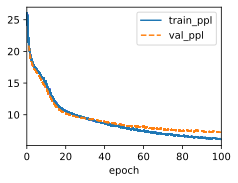

In [85]:
data = d2l.TimeMachine(batch_size=1024, num_steps=32)
rnn = RNNScratch(num_inputs=len(data.vocab), num_hiddens=32)
model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=1)
trainer = d2l.Trainer(max_epochs=100, gradient_clip_val=1, num_gpus=1)
trainer.fit(model, data)

### 9.5.5 Decoding
* Once a language model has been learned, we can use it to predict next token, but to keep predicting each subsequent one, treating the previously model-predicted token as part of the input of the next
* Often useful to condition languag emodel on user-supplied prefix (e.g. autocomplete feature)
* "predict" method below generates a continuation of one character at a time, after ingesting a user-provided "prefix"
* When looping through characters in "prefix", we keep passing hidden state to next time step but do not generate any output - this is called the _warp-up_ period

In [86]:
@d2l.add_to_class(RNNLMScratch) 
def predict(self, prefix, num_preds, vocab, device=None):
    state, outputs = None, [vocab[prefix[0]]]
    for i in range(len(prefix) + num_preds - 1):
        X = torch.tensor([[outputs[-1]]], device=device)
        embs = self.one_hot(X)
        rnn_outputs, state = self.rnn(embs, state)
        if i < len(prefix) - 1:  # Warm-up period
            outputs.append(vocab[prefix[i + 1]])
        else:  # Predict num_preds steps
            Y = self.output_layer(rnn_outputs)
            outputs.append(int(Y.argmax(axis=2).reshape(1)))
    return ''.join([vocab.idx_to_token[i] for i in outputs])

In [90]:
model.predict(prefix='it has', num_preds=40, vocab=data.vocab, device=d2l.try_gpu())

'it has our the the time the time the time the '

### 9.5.6 Summary
* Can train RNN-based language models to generate text following user-provided text-prefix
* Simple RNN language model consists of:
    * Input encoding
    * RNN modeling
    * Output generation 
* Gradient clipping is a heuristic method that can mitigate problem of exploding gradients (but not vanishing gradients)
* By conditioning language model on a prefix, we can use a language model to generate likely continuations, which is useful in applications such as autocomplete

### 9.5.7 Exercises
1. Does the implemented language model predict the next token based on all the past tokens up to the very first token in *The Time Machine*? 
1. Which hyperparameter controls the length of history used for prediction?
1. Show that one-hot encoding is equivalent to picking a different embedding for each object.
1. Adjust the hyperparameters (e.g., number of epochs, number of hidden units, number of time steps in a minibatch, and learning rate) to improve the perplexity. How low can you go while sticking with this simple architecture?
1. Replace one-hot encoding with learnable embeddings. Does this lead to better performance?
1. Conduct an experiment to determine how well this language model 
   trained on *The Time Machine* works on other books by H. G. Wells,
   e.g., *The War of the Worlds*.
1. Conduct another experiment to evaluate the perplexity of this model
   on books written by other authors. 
1. Modify the prediction method so as to use sampling 
   rather than picking the most likely next character.
    * What happens?
    * Bias the model towards more likely outputs, e.g., 
    by sampling from $q(x_t \mid x_{t-1}, \ldots, x_1) \propto P(x_t \mid x_{t-1}, \ldots, x_1)^\alpha$ for $\alpha > 1$.
1. Run the code in this section without clipping the gradient. What happens?
1. Replace the activation function used in this section with ReLU 
   and repeat the experiments in this section. Do we still need gradient clipping? Why?

Exercise #1
* For predicting the next token, no it does not predict the next token based on all past tokens upp to very first token in _The Time Machine_. It will only do so if the entire text of _The Time Machine_ is supplied as the prefix, but will not do so as default

Exercise #2
* **num_steps** controls history length by determining the length of each training subsequence

Exercise #3
* Showing that one-hot encoding is equivalent to picking a different embedding for each object 

# 9.6 Concise Implementation of Recurrent Neural Networks

### 9.6.1 Defining the Model

### 9.6.2 Training and Predicting

### 9.6.3 Summary

### 9.6.4 Exercises
1. Can you make the RNN model overfit using the high-level APIs?
1. Implement the autoregressive model of Section 9.1 using an RNN.

# 9.7 Backpropagation Through Time

### 9.7.1 Analysis of Gradients in RNNs

### 9.7.2 Backpropagation Through Time in Detail

### 9.7.3 Summary

### 9.7.4 Exercises
1. Assume that we have a symmetric matrix $\mathbf{M} \in \mathbb{R}^{n \times n}$ with eigenvalues $\lambda_i$ whose corresponding eigenvectors are $\mathbf{v}_i$ ($i = 1, \ldots, n$). Without loss of generality, assume that they are ordered in the order $|\lambda_i| \geq |\lambda_{i+1}|$. 
   1. Show that $\mathbf{M}^k$ has eigenvalues $\lambda_i^k$.
   1. Prove that for a random vector $\mathbf{x} \in \mathbb{R}^n$, with high probability $\mathbf{M}^k \mathbf{x}$ will be very much aligned with the eigenvector $\mathbf{v}_1$ 
of $\mathbf{M}$. Formalize this statement.
   1. What does the above result mean for gradients in RNNs?
1. Besides gradient clipping, can you think of any other methods to cope with gradient explosion in recurrent neural networks?